In [1]:
import pandas as pd 
aqidata = pd.read_csv('master_refinery_aqi.csv',parse_dates=['Timestamp'],index_col='Timestamp')
columns_to_drop = ['Xylene (µg/m³)','O Xylene (µg/m³)','Eth-Benzene (µg/m³)','MP-Xylene (µg/m³)','RF (mm)','VWS (m/s)']
aqidata = aqidata.drop(columns=columns_to_drop)
aqidata = aqidata.interpolate(method='time')
aqidata = aqidata.dropna()
print(aqidata.shape)

(26304, 18)


ARIMA RMSE:220.78
Epoch 1/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 91ms/step - loss: 0.0294 - val_loss: 0.0108 - learning_rate: 0.0010
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - loss: 0.0228 - val_loss: 0.0107 - learning_rate: 0.0010
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - loss: 0.0219 - val_loss: 0.0112 - learning_rate: 0.0010
Epoch 4/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 276ms/step - loss: 0.0209 - val_loss: 0.0111 - learning_rate: 0.0010
Epoch 5/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - loss: 0.0222 - val_loss: 0.0148 - learning_rate: 0.0010
Epoch 6/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 0.0210 - val_loss: 0.0106 - learning_rate: 0.0010
Epoch 7/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 0.0204 - val_loss: 0.0109 - learning_rate: 0.0010
Epoch 8/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 0.0199 - val_loss: 0.0109 - learning_rate: 0.0010
Epoch 9/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 121ms/step - loss: 0.0188 - val_loss: 0.0108 - learning

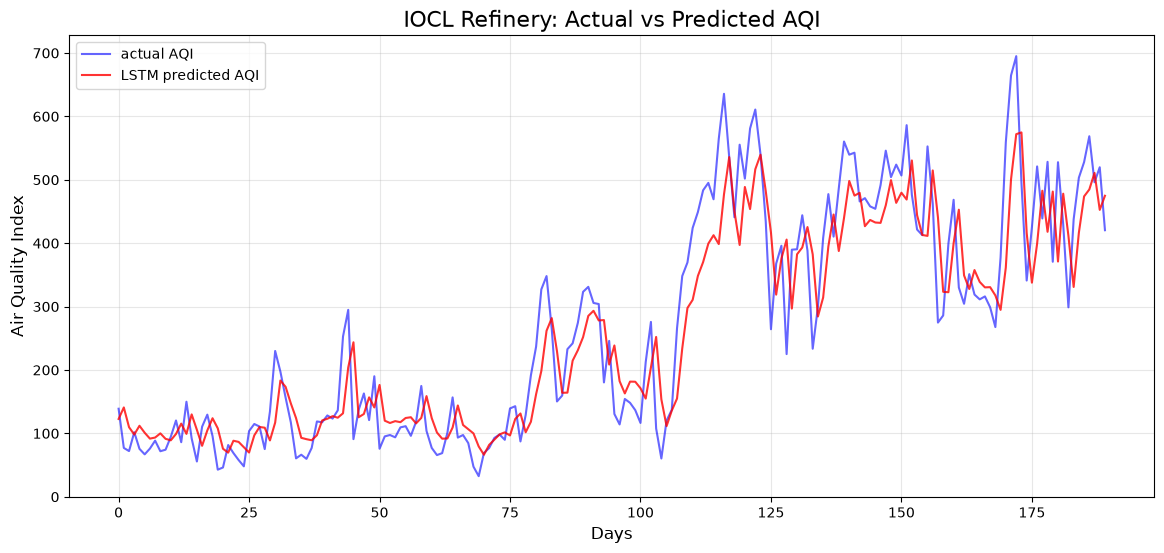

In [2]:

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense,Dropout,Input
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau

dailydata = aqidata.resample('D').mean()
dailydata['AQI'] = dailydata[['PM2.5 (µg/m³)', 'PM10 (µg/m³)']].max(axis=1)
dailydata = dailydata.dropna()
aqivalues = dailydata['AQI'].values
trainsize = int(len(aqivalues)*0.8)
train = aqivalues[:trainsize]
test = aqivalues[trainsize:]

# implementing ARIMA model
modeltrain = ARIMA(train,order=(5,1,0))
result = modeltrain.fit() #using arima

predictions = result.forecast(steps=len(test))
rmse = np.sqrt(mean_squared_error(test,predictions))
print(f"ARIMA RMSE:{rmse:.2f}")

#implementing LSTM model

scaler = MinMaxScaler(feature_range=(0,1))
scaleddata = scaler.fit_transform(aqivalues.reshape(-1,1))
trainscaled = scaleddata[:trainsize]
testscaled = scaleddata[trainsize:]

def create_sequence(data,seqlength):
    x,y = [],[]
    for i in range(len(data)-seqlength):
        x.append(data[i:(i+seqlength),0])
        y.append(data[i+seqlength,0])
    return np.array(x),np.array(y)

seqlength = 30
xtrain,ytrain = create_sequence(trainscaled,seqlength)
xtest,ytest = create_sequence(testscaled,seqlength)

xtrain = np.reshape(xtrain,(xtrain.shape[0],xtrain.shape[1],1))
xtest = np.reshape(xtest,(xtest.shape[0],xtest.shape[1],1))

lstmmodel = Sequential()
lstmmodel.add(Input(shape=(seqlength, 1)))          
lstmmodel.add(LSTM(128, return_sequences=True))     
lstmmodel.add(Dropout(0.2))
lstmmodel.add(LSTM(64, return_sequences=True))      
lstmmodel.add(Dropout(0.2))
lstmmodel.add(LSTM(32, return_sequences=False))     
lstmmodel.add(Dropout(0.2))
lstmmodel.add(Dense(1))

earlystop = EarlyStopping(monitor='val_loss',patience=15,restore_best_weights=True)
reducelr = ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=7,min_lr=0.00001)

lstmmodel.compile(optimizer='adam',loss='mean_squared_error')
lstmmodel.fit(xtrain,ytrain,batch_size=16,epochs=100,validation_split=0.1,callbacks=[earlystop,reducelr],verbose=1)

lstmpredictions = lstmmodel.predict(xtest)
lstmpredictions = scaler.inverse_transform(lstmpredictions)
actualtest = scaler.inverse_transform(ytest.reshape(-1,1))

lstmrmse = np.sqrt(mean_squared_error(actualtest,lstmpredictions))
print(f"LSTM RMSE:{lstmrmse:.2f}")

plt.figure(figsize=(14,6))
plt.plot(actualtest,color='blue',label='actual AQI',alpha=0.6)
plt.plot(lstmpredictions,color='red',label='LSTM predicted AQI',alpha=0.8)
plt.title('IOCL Refinery: Actual vs Predicted AQI',fontsize=16)
plt.xlabel('Days',fontsize=12)
plt.ylabel('Air Quality Index',fontsize=12)
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()